# Análise: detecção e mascaramento de obscenidades em letras musicais brasileiras

Este notebook reúne os dados gerados pelos scripts do projeto de Teoria de Linguagens sobre 1.150 letras de músicas brasileiras. A análise está dividida em quatro partes:

1. Desempenho dos motores de expressões regulares em Julia, TypeScript, Java e C#. Comparamos o tempo total de execução, o tempo para compilar a expressão regular, o tempo gasto apenas na busca pelo texto, o custo médio por caractere, a vazão de leitura e o comportamento linear $O(n)$.
2. Frequência de cada obscenidade do catálogo (`lib/swear-words.json`). Avaliamos quantas vezes cada termo aparece, em quantas músicas diferentes ele surge e qual é o seu peso no total, tanto no conjunto completo quanto por gênero e por década.
3. Presença de obscenidades nas faixas. Medimos o total de ocorrências, o percentual de músicas com ao menos uma obscenidade e a densidade de obscenidades por gênero musical, por década e por artista.
4. Relação com o vocabulário geral (`incidence:words`). Verificamos quais obscenidades aparecem entre as palavras mais usadas do conjunto de letras, tanto no ranking geral quanto no recorte por gênero.

## 1. Dicionário de métricas

Esta seção explica o significado de cada coluna exibida nas tabelas e nos gráficos do notebook.

### Métricas de desempenho dos motores de regex

| Métrica | Como é calculada | O que ela mostra na prática |
| :--- | :--- | :--- |
| Tempo total (ms) | Leitura dos arquivos + compilação da regex + busca + gravação | Tempo completo sentido do início ao fim da execução, incluindo 2.300 operações de leitura e escrita em disco. |
| Compilação da regex (ms) | Construção da árvore de prefixos (Trie) + compilação do padrão | Tempo inicial gasto para montar o autômato da expressão regular antes de começar a ler as letras. |
| Tempo de busca (ms) | Soma do tempo gasto apenas na função `maskText` nas 1.150 letras | Velocidade real do motor de regex em memória, sem interferência da lentidão do disco. |
| Custo por caractere (ns/char) | $\frac{\text{Tempo de busca (ns)}}{\text{Total de caracteres}}$ | Tempo médio em nanossegundos para processar um único caractere, permitindo comparar textos de tamanhos diferentes. |
| Caracteres por ms e Vazão (MB/s) | $\frac{\text{Caracteres}}{\text{Tempo de busca (ms)}}$ e $\frac{\text{Bytes UTF-8}}{\text{Tempo de busca (s)} \times 10^6}$ | Volume de texto que cada linguagem consegue processar por unidade de tempo. Quanto maior, mais rápido o motor. |
| Correlação (r) e Ajuste linear (R²) | Correlação de Pearson entre tamanho da letra ($n$) e tempo de busca ($\mu s$) | Indica se o tempo cresce de forma proporcional ao tamanho do texto, testando na prática a complexidade linear $O(n)$. |

### Métricas linguísticas e lexicais

| Métrica | Como é calculada | O que ela mostra na prática |
| :--- | :--- | :--- |
| Palavras totais | Palavras extraídas das letras (sem tags como `[Refrão]`, pontuação ou termos com menos de 2 letras) | Volume bruto de palavras válidas encontradas nas músicas antes de qualquer filtragem. |
| Palavras úteis | Palavras totais após remover palavras muito comuns (`lib/ignore-words.json`), como artigos e preposições | Base de vocabulário com carga de significado, usada no cálculo do comando `incidence:words`. |
| Vocabulário único | Contagem de palavras diferentes entre as palavras úteis | Diversidade lexical do gênero ou do conjunto analisado. |
| Ocorrências | Soma de todas as aparições do termo, contando repetições | Frequência absoluta de uma obscenidade no conjunto, gênero ou década. |
| Difusão nas faixas (%) | $\frac{\text{Faixas com o termo}}{\text{Total de faixas do grupo}} \times 100$ | Alcance real do termo. Mostra em qual parcela das músicas ele aparece, evitando que um único refrão repetitivo distorça a leitura. |
| Participação (%) | $\frac{\text{Ocorrências do termo}}{\text{Total de ocorrências do grupo}} \times 100$ | Fatia que aquele termo, gênero ou década representa dentro do total analisado. |
| Densidade (a cada 1.000 chars) | $\frac{\text{Total de obscenidades}}{\text{Total de caracteres}} \times 1000$ | Taxa proporcional de obscenidades por tamanho de texto. Permite comparar gêneros com letras longas (como rap) e letras curtas (como funk e rock) de forma justa. |

In [21]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATASETS_DIR: Path = Path("datasets")
if not DATASETS_DIR.exists():
    DATASETS_DIR = Path("data-analysis/datasets")

plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

COLUMN_LABELS: dict[str, str] = {
    "language": "Linguagem",
    "elapsed_ms": "Tempo total (ms)",
    "regex_compile_ms": "Compilação da regex (ms)",
    "matching_time_ms": "Tempo de busca (ms)",
    "ns_per_char": "Custo por caractere (ns/char)",
    "chars_per_ms": "Caracteres por ms",
    "throughput_mbs": "Vazão (MB/s)",
    "pearson_r": "Correlação (r)",
    "r_squared": "Ajuste linear (R²)",
    "canonical_term": "Obscenidade",
    "occurrences": "Ocorrências",
    "tracks_with_term": "Faixas com o termo",
    "diffusion_pct": "Difusão nas faixas (%)",
    "share_of_swears_pct": "Participação nas obscenidades (%)",
    "genre": "Gênero",
    "genres": "Gêneros",
    "decade": "Década",
    "artist": "Artista",
    "total_tracks": "Total de faixas",
    "tracks_with_swear": "Faixas com obscenidade",
    "tracks_with_swear_pct": "Faixas com obscenidade (%)",
    "total_swears": "Total de obscenidades",
    "share_of_corpus_swears_pct": "Participação no corpus (%)",
    "avg_swears_per_track": "Média por faixa",
    "avg_swears_per_swear_track": "Média nas faixas com obscenidade",
    "total_characters": "Total de caracteres",
    "swear_density_per_1k_chars": "Densidade (a cada 1.000 chars)",
    "raw_tokens": "Palavras totais",
    "filtered_tokens": "Palavras úteis",
    "unique_words": "Vocabulário único",
    "rank": "Posição no ranking",
    "word": "Palavra",
    "track_count": "Faixas com a palavra",
    "share_pct": "Participação no vocabulário (%)",
    "swears_in_top_100": "Obscenidades no Top 100",
}


def load_dataset(file_name: str) -> pd.DataFrame:
    """Loads a CSV file from the consolidated datasets directory."""
    return pd.read_csv(DATASETS_DIR / file_name)


def format_for_display(df: pd.DataFrame) -> pd.DataFrame:
    """Returns a copy of the DataFrame with human-readable Portuguese column labels."""
    return df.rename(columns=COLUMN_LABELS)


benchmark_summary_df = load_dataset("benchmarkSummary.csv")
benchmark_linearity_df = load_dataset("benchmarkLinearity.csv")
tracks_df = load_dataset("tracksDataset.csv")
matches_detail_df = load_dataset("swearMatchesDetail.csv")
swear_overall_df = load_dataset("swearWordsOverall.csv")
swear_by_genre_df = load_dataset("swearWordsByGenre.csv")
swear_by_decade_df = load_dataset("swearWordsByDecade.csv")
genre_summary_df = load_dataset("genreSummary.csv")
decade_summary_df = load_dataset("decadeSummary.csv")
decade_by_genre_df = load_dataset("decadeByGenreSummary.csv")
artist_summary_df = load_dataset("artistSummary.csv")
incidence_global_df = load_dataset("incidenceTopWordsGlobal.csv")
incidence_genre_df = load_dataset("incidenceTopWordsByGenre.csv")

print(f"Arquivos carregados de: {DATASETS_DIR.resolve()}")
print(f"Total de faixas: {len(tracks_df)} | Total de ocorrências encontradas: {len(matches_detail_df)}")

Arquivos carregados de: C:\projects\scripts-teoria-de-linguagens\data-analysis\datasets
Total de faixas: 1150 | Total de ocorrências encontradas: 5244


## 2. Desempenho dos motores de regex (Julia, TypeScript, Java e C#)

A tabela abaixo ordena as linguagens do menor para o maior tempo de busca em memória. Separar o tempo de busca do tempo total evita que a leitura e gravação de arquivos no disco escondam a diferença real entre os motores de expressão regular.

Logo depois, os gráficos comparam o tempo de busca, o custo por caractere e a vazão de leitura, seguidos pelos gráficos de dispersão que verificam se o tempo cresce de forma linear conforme a letra aumenta.

In [22]:
display_cols = [
    "language",
    "elapsed_ms",
    "regex_compile_ms",
    "matching_time_ms",
    "ns_per_char",
    "chars_per_ms",
    "throughput_mbs",
    "pearson_r",
    "r_squared",
]
format_for_display(benchmark_summary_df[display_cols].sort_values("matching_time_ms"))

,Linguagem,Tempo total (ms),Compilação da regex (ms),Tempo de busca (ms),Custo por caractere (ns/char),Caracteres por ms,Vazão (MB/s),Correlação (r),Ajuste linear (R²)
0,Julia,666.07,1.2802,31.31,13.72,72880.20,74.93,0.8837,0.7809
1,TypeScript,1080.99,10.6019,41.47,18.18,55016.35,56.57,0.2671,0.0713
2,Java,1022.49,10.5785,201.53,88.32,11322.22,11.64,0.4785,0.2289
3,C#,1071.73,11.7141,325.50,142.66,7009.91,7.21,0.6668,0.4446


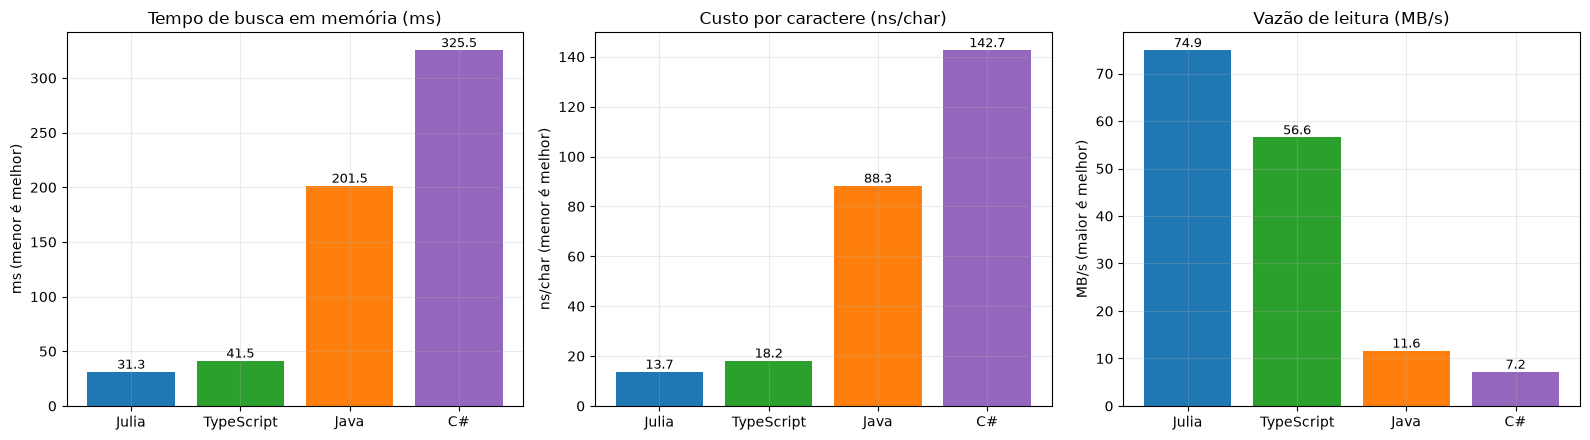

In [23]:
ordered_bench = benchmark_summary_df.sort_values("matching_time_ms")
colors = ["#1f77b4", "#2ca02c", "#ff7f0e", "#9467bd"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].bar(ordered_bench["language"], ordered_bench["matching_time_ms"], color=colors)
axes[0].set_title("Tempo de busca em memória (ms)")
axes[0].set_ylabel("ms (menor é melhor)")
for idx, val in enumerate(ordered_bench["matching_time_ms"]):
    axes[0].text(idx, val, f"{val:.1f}", ha="center", va="bottom", fontsize=9)

# TODO: substituir por análise de "elapsed_ms"
axes[1].bar(ordered_bench["language"], ordered_bench["ns_per_char"], color=colors)
axes[1].set_title("Custo por caractere (ns/char)")
axes[1].set_ylabel("ns/char (menor é melhor)")
for idx, val in enumerate(ordered_bench["ns_per_char"]):
    axes[1].text(idx, val, f"{val:.1f}", ha="center", va="bottom", fontsize=9)

axes[2].bar(ordered_bench["language"], ordered_bench["throughput_mbs"], color=colors)
axes[2].set_title("Vazão de leitura (MB/s)")
axes[2].set_ylabel("MB/s (maior é melhor)")
for idx, val in enumerate(ordered_bench["throughput_mbs"]):
    axes[2].text(idx, val, f"{val:.1f}", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

## 3. Frequência, difusão e participação de cada obscenidade

Esta seção analisa os 161 termos cadastrados em `lib/swear-words.json`, agrupando variações de plural, acentuação e censura sob o mesmo termo base.

A tabela e o gráfico mostram as 25 obscenidades mais frequentes em todo o conjunto de letras. Olhar a difusão junto com o total de ocorrências ajuda a distinguir termos comuns em várias músicas daqueles que aparecem muitas vezes em poucas faixas. Em seguida, duas tabelas cruzam os 15 termos mais frequentes por gênero musical e por década.

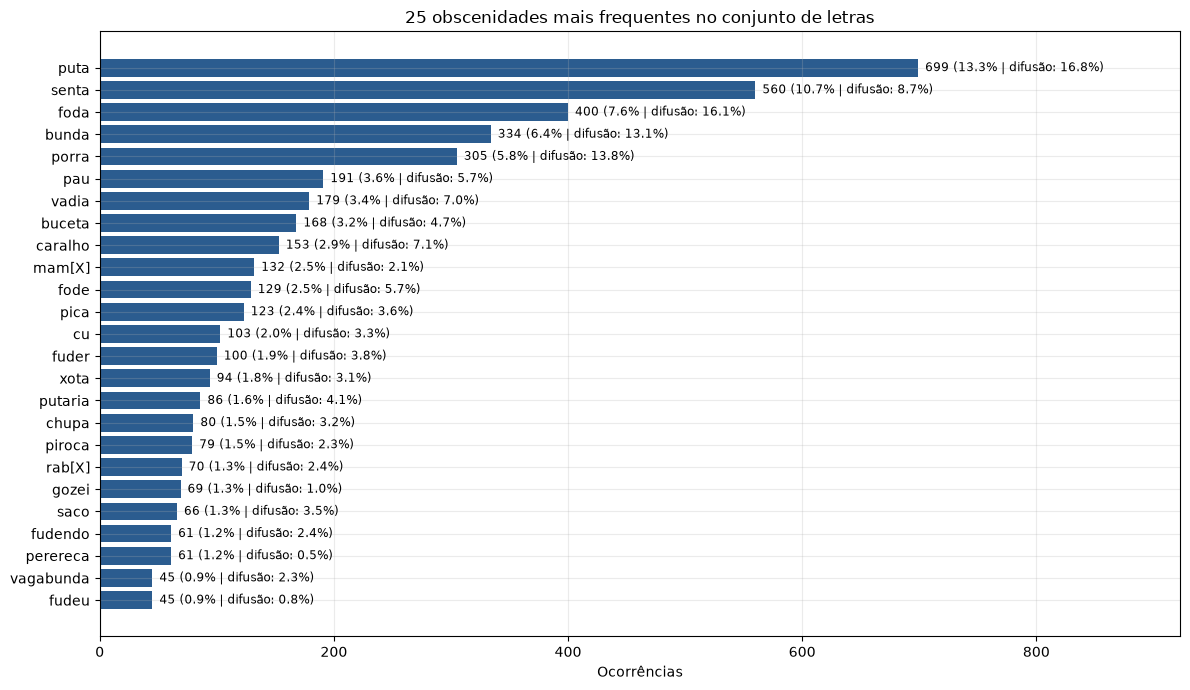

In [24]:
top_25_terms = swear_overall_df.head(25)

fig, ax = plt.subplots(figsize=(12, 7))
plot_data = top_25_terms.iloc[::-1]
ax.barh(plot_data["canonical_term"], plot_data["occurrences"], color="#2b5c8f")
ax.set_title("25 obscenidades mais frequentes no conjunto de letras")
ax.set_xlabel("Ocorrências")
for idx, (_, row) in enumerate(plot_data.iterrows()):
    ax.text(
        row["occurrences"] + 6,
        idx,
        f"{int(row['occurrences'])} ({row['share_of_swears_pct']:.1f}% | difusão: {row['diffusion_pct']:.1f}%)",
        va="center",
        fontsize=8.5,
    )
ax.set_xlim(0, top_25_terms["occurrences"].max() * 1.32)
plt.tight_layout()
plt.show()

In [25]:
top_15_names = swear_overall_df.head(15)["canonical_term"].tolist()
pivot_genre = (
    swear_by_genre_df[swear_by_genre_df["canonical_term"].isin(top_15_names)]
    .pivot(index="canonical_term", columns="genre", values="occurrences")
    .fillna(0)
    .astype(int)
    .reindex(top_15_names)
    .rename_axis(index="Obscenidade", columns="Gênero")
)
print("Ocorrências das 15 obscenidades mais frequentes por gênero:")
display(pivot_genre)

Ocorrências das 15 obscenidades mais frequentes por gênero:


Gênero,funk,rap,rock,sertanejo,trap,trap-extra
Obscenidade,,,,,,
puta,321,58,21,0,169,130
senta,364,61,0,60,40,35
foda,76,143,4,6,81,90
bunda,112,67,7,1,76,71
porra,82,76,5,13,78,51
pau,82,8,23,0,43,35
vadia,7,20,0,0,52,100
buceta,90,11,3,9,35,20
caralho,84,26,1,0,30,12


In [26]:
pivot_decade = (
    swear_by_decade_df[swear_by_decade_df["canonical_term"].isin(top_15_names)]
    .pivot(index="canonical_term", columns="decade", values="occurrences")
    .fillna(0)
    .astype(int)
    .reindex(top_15_names)
    .rename_axis(index="Obscenidade", columns="Década")
)
print("Ocorrências das 15 obscenidades mais frequentes por década:")
display(pivot_decade)

Ocorrências das 15 obscenidades mais frequentes por década:


Década,1980s,1990s,2000s,2010s,2020s,Desconhecida
Obscenidade,,,,,,
puta,1,3,16,60,619,0
senta,0,1,0,64,495,0
foda,0,1,0,92,307,0
bunda,0,0,7,57,270,0
porra,0,2,1,32,270,0
pau,0,20,3,20,148,0
vadia,0,0,0,10,168,1
buceta,0,0,0,22,145,1
caralho,0,1,0,15,137,0


## 4. Presença de obscenidades por gênero, década e artista

Aqui comparamos em qual parcela das músicas aparecem obscenidades, quantas ocorrências existem no total e qual é a densidade a cada 1.000 caracteres. A densidade corrige a diferença de tamanho entre as letras, permitindo comparar gêneros com textos longos e curtos na mesma escala.

A seção também traz o recorte por década de lançamento, o cruzamento entre década e gênero e o ranking de artistas com mais ocorrências e maior proporção de faixas com obscenidades.

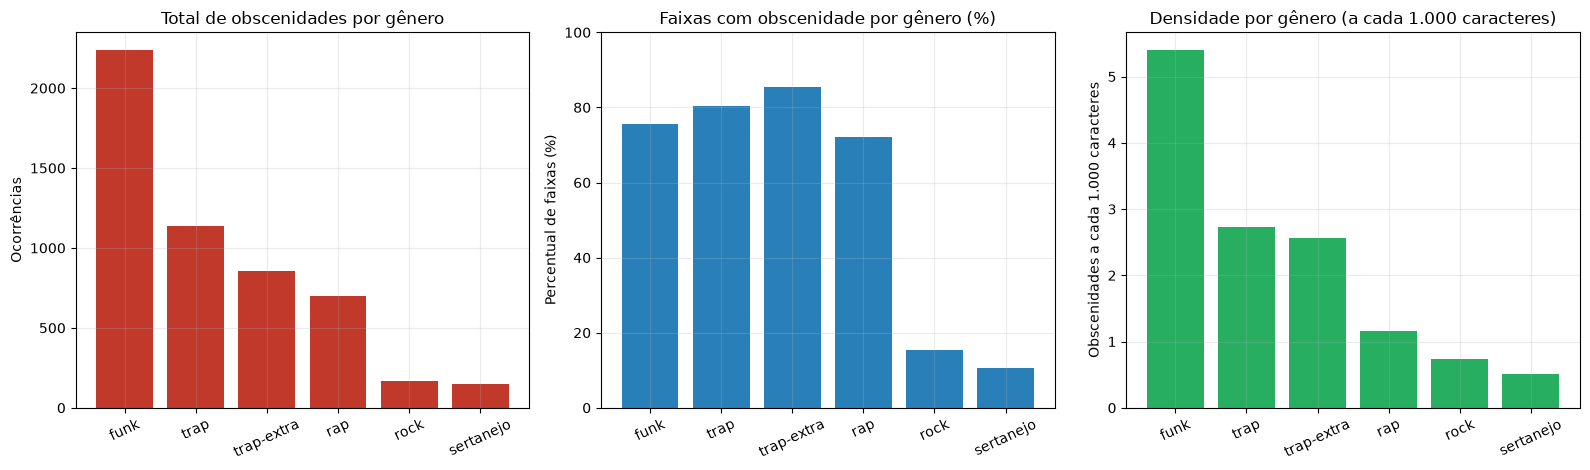

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

axes[0].bar(genre_summary_df["genre"], genre_summary_df["total_swears"], color="#c0392b")
axes[0].set_title("Total de obscenidades por gênero")
axes[0].set_ylabel("Ocorrências")
axes[0].tick_params(axis="x", rotation=25)

axes[1].bar(genre_summary_df["genre"], genre_summary_df["tracks_with_swear_pct"], color="#2980b9")
axes[1].set_title("Faixas com obscenidade por gênero (%)")
axes[1].set_ylabel("Percentual de faixas (%)")
axes[1].set_ylim(0, 100)
axes[1].tick_params(axis="x", rotation=25)

axes[2].bar(genre_summary_df["genre"], genre_summary_df["swear_density_per_1k_chars"], color="#27ae60")
axes[2].set_title("Densidade por gênero (a cada 1.000 caracteres)")
axes[2].set_ylabel("Obscenidades a cada 1.000 caracteres")
axes[2].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

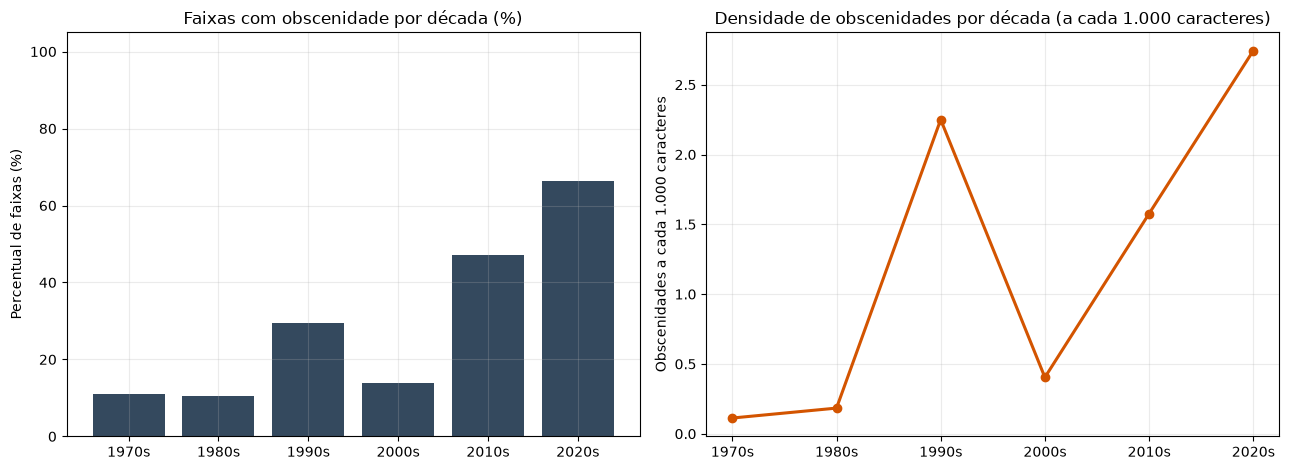

Cruzamento entre década e gênero:


,Década,Gênero,Total de faixas,Faixas com obscenidade,Faixas com obscenidade (%),Total de obscenidades,Média por faixa
0,1960s,rock,1,1,100.00,7,7.00
1,1970s,rock,9,1,11.11,1,0.11
2,1980s,rock,19,2,10.53,5,0.26
3,1990s,rock,31,9,29.03,81,2.61
4,1990s,sertanejo,2,0,0.00,0,0.00
5,1990s,trap-extra,1,1,100.00,16,16.00
6,2000s,funk,1,0,0.00,0,0.00
7,2000s,rap,8,5,62.50,11,1.38
8,2000s,rock,86,9,10.47,46,0.53
9,2000s,sertanejo,5,0,0.00,0,0.00


In [28]:
# Filtra por décadas com indíce conhecido e que possuam no mínimo 5 músicas
decades = decade_summary_df[decade_summary_df["decade"] != "Desconhecida"]
valid_decades = decades[decades["total_tracks"] >= 5]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

axes[0].bar(valid_decades["decade"], valid_decades["tracks_with_swear_pct"], color="#34495e")
axes[0].set_title("Faixas com obscenidade por década (%)")
axes[0].set_ylabel("Percentual de faixas (%)")
axes[0].set_ylim(0, 105)

axes[1].plot(
    valid_decades["decade"],
    valid_decades["swear_density_per_1k_chars"],
    marker="o",
    linewidth=2.2,
    color="#d35400",
)
axes[1].set_title("Densidade de obscenidades por década (a cada 1.000 caracteres)")
axes[1].set_ylabel("Obscenidades a cada 1.000 caracteres")

plt.tight_layout()
plt.show()

print("Cruzamento entre década e gênero:")
display(format_for_display(decade_by_genre_df))

In [29]:
print("20 artistas com maior total de obscenidades:")
display(format_for_display(artist_summary_df.head(20)))

print("20 artistas (com pelo menos 5 faixas) por percentual de faixas com obscenidade:")
frequent_artists = (
    artist_summary_df[artist_summary_df["total_tracks"] >= 5]
    .sort_values(["tracks_with_swear_pct", "total_swears"], ascending=[False, False])
    .head(20)
)
display(format_for_display(frequent_artists))

20 artistas com maior total de obscenidades:


,Artista,Total de faixas,Faixas com obscenidade,Faixas com obscenidade (%),Total de obscenidades,Média por faixa,Gêneros
0,MC Ryan SP,21,20,95.24,420,20.00,funk; rap
1,MC Meno K,17,16,94.12,369,21.71,funk
2,MC GP,8,7,87.50,280,35.00,funk; trap
3,LUCKHAOS,13,13,100.00,272,20.92,trap
4,MC Jvila,8,8,100.00,262,32.75,funk
5,NGC Daddy,19,19,100.00,254,13.37,trap
6,Derek,26,24,92.31,251,9.65,trap; trap-extra
7,Aaron Modesto,6,6,100.00,249,41.50,funk
8,Mc Lele JP,15,15,100.00,236,15.73,funk
9,DJ Glenner,3,3,100.00,218,72.67,funk


20 artistas (com pelo menos 5 faixas) por percentual de faixas com obscenidade:


,Artista,Total de faixas,Faixas com obscenidade,Faixas com obscenidade (%),Total de obscenidades,Média por faixa,Gêneros
3,LUCKHAOS,13,13,100.0,272,20.92,trap
4,MC Jvila,8,8,100.0,262,32.75,funk
5,NGC Daddy,19,19,100.0,254,13.37,trap
7,Aaron Modesto,6,6,100.0,249,41.50,funk
8,Mc Lele JP,15,15,100.0,236,15.73,funk
17,"Ryu, the Runner",18,18,100.0,138,7.67,trap; trap-extra
19,Mc Negão Original,9,9,100.0,116,12.89,funk
20,TTF,7,7,100.0,108,15.43,trap-extra
21,Mc Jacaré,9,9,100.0,107,11.89,funk
32,MC Rick,11,11,100.0,86,7.82,funk


## 5. Obscenidades entre as palavras mais frequentes (`incidence:words`)

Esta última etapa cruza o catálogo de obscenidades com o ranking gerado pelo comando `incidence:words`, considerando as 200 palavras mais usadas no conjunto geral e as 100 mais usadas em cada gênero. O objetivo é verificar se alguma obscenidade chega a figurar entre os termos mais comuns do vocabulário das letras.

In [30]:
global_swears_in_top = incidence_global_df[incidence_global_df["is_swear_word"] == True].drop(
    columns=["is_swear_word"]
)
print(f"Obscenidades entre as 200 palavras mais frequentes do corpus: {len(global_swears_in_top)}")
display(format_for_display(global_swears_in_top))

genre_swears_in_top = incidence_genre_df[incidence_genre_df["is_swear_word"] == True].drop(
    columns=["is_swear_word"]
)
print("\nQuantidade de obscenidades entre as 100 palavras mais frequentes de cada gênero:")
genre_counts = (
    genre_swears_in_top.groupby("genre")["word"]
    .count()
    .reset_index(name="swears_in_top_100")
)
display(format_for_display(genre_counts))

print("\nDetalhamento das obscenidades no Top 100 por gênero:")
display(format_for_display(genre_swears_in_top))

Obscenidades entre as 200 palavras mais frequentes do corpus: 9


,Posição no ranking,Palavra,Ocorrências,Faixas com a palavra,Difusão nas faixas (%),Participação no vocabulário (%)
18,19,puta,653,177,15.4,0.32
25,26,senta,559,100,8.7,0.27
54,55,bunda,331,148,12.9,0.16
63,64,porra,304,158,13.7,0.15
78,79,foda,272,131,11.4,0.13
133,134,pau,187,63,5.5,0.09
159,160,buceta,166,53,4.6,0.08
167,168,vadia,161,73,6.3,0.08
187,188,caralho,152,81,7.0,0.07



Quantidade de obscenidades entre as 100 palavras mais frequentes de cada gênero:


,Gênero,Obscenidades no Top 100
0,funk,13
1,rap,3
2,sertanejo,1
3,trap,6
4,trap-extra,6



Detalhamento das obscenidades no Top 100 por gênero:


,Gênero,Posição no ranking,Palavra,Ocorrências,Faixas com a palavra,Difusão nas faixas (%),Participação no vocabulário (%)
51,rap,52,foda,93,48,24.0,0.17
68,rap,69,porra,76,47,23.5,0.14
86,rap,87,bunda,67,33,16.5,0.12
102,funk,3,senta,363,42,21.0,0.93
103,funk,4,puta,315,43,21.5,0.81
132,funk,33,bunda,112,32,16.0,0.29
145,funk,46,buceta,90,17,8.5,0.23
152,funk,53,caralho,84,33,16.5,0.22
156,funk,57,porra,82,33,16.5,0.21
159,funk,60,pau,80,20,10.0,0.21
